<a href="https://colab.research.google.com/github/anythingfornow-ux/Flat-Plate-Flight-Stability-CFD/blob/main/notebooks/diamond_wing_3d_cfd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:

# ============================================================
# 3D DIAMOND FLAT-PLATE WING CFD PREPROCESSING
# Self-contained Google Colab code
# Creates:
# 1. 3D diamond wing
# 2. Surrounding airflow domain
# 3. Preliminary tetrahedral volume mesh
# 4. STL and MSH output files
# ============================================================

import os
import sys
import subprocess

# STEP 1: Install system and Python dependencies
print("Installing required libraries...")

subprocess.run(
    ["apt-get", "update", "-qq"],
    check=True
)

subprocess.run(
    ["apt-get", "install", "-y", "libglu1-mesa", "libgl1"],
    check=True
)

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "gmsh==4.13.1"],
    check=True
)

import gmsh
import math

print("Libraries installed successfully.")

# STEP 2: Define geometry in metres
SIDE = 0.99
THICKNESS = 0.010

D = SIDE * math.sqrt(2.0)

# STEP 3: Start Gmsh
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 1)

try:
    gmsh.model.add("Diamond_Wing_3D")

    # STEP 4: Create large airflow box
    x_min = -5.0 * D
    x_max = 11.0 * D
    y_min = -3.0 * D
    y_max = 3.0 * D
    z_min = -3.0 * D
    z_max = 3.0 * D

    air_box = gmsh.model.occ.addBox(
        x_min, y_min, z_min,
        x_max - x_min,
        y_max - y_min,
        z_max - z_min
    )

    # STEP 5: Create diamond wing
    vertices = [
        (0.0, 0.0),
        (D / 2.0, D / 2.0),
        (D, 0.0),
        (D / 2.0, -D / 2.0)
    ]

    points = []

    for x, y in vertices:
        points.append(
            gmsh.model.occ.addPoint(
                x, y, -THICKNESS / 2.0
            )
        )

    edges = []

    for i in range(4):
        edges.append(
            gmsh.model.occ.addLine(
                points[i],
                points[(i + 1) % 4]
            )
        )

    loop = gmsh.model.occ.addCurveLoop(edges)
    face = gmsh.model.occ.addPlaneSurface([loop])

    # Extrude flat plate to 10 mm thickness
    extrusion = gmsh.model.occ.extrude(
        [(2, face)],
        0.0, 0.0, THICKNESS
    )

    wing_volumes = [
        (dim, tag)
        for dim, tag in extrusion
        if dim == 3
    ]

    # STEP 6: Create air volume around the wing
    fluid, _ = gmsh.model.occ.cut(
        [(3, air_box)],
        wing_volumes
    )

    gmsh.model.occ.synchronize()

    fluid_tags = [
        tag for dim, tag in fluid
        if dim == 3
    ]

    if len(fluid_tags) == 0:
        raise RuntimeError(
            "No fluid volume was created."
        )

    gmsh.model.addPhysicalGroup(
        3, fluid_tags, 1
    )

    gmsh.model.setPhysicalName(
        3, 1, "Air"
    )

    # STEP 7: Set mesh size
    gmsh.option.setNumber(
        "Mesh.MeshSizeMin", 0.20
    )

    gmsh.option.setNumber(
        "Mesh.MeshSizeMax", 0.50
    )

    gmsh.option.setNumber(
        "Mesh.Algorithm3D", 1
    )

    gmsh.option.setNumber(
        "Mesh.MshFileVersion", 2.2
    )

    # STEP 8: Generate 3D mesh
    print("Generating 3D tetrahedral mesh...")
    gmsh.model.mesh.generate(3)

    # STEP 9: Save mesh and geometry
    gmsh.write(
        "/content/diamond_wing_airflow_domain.msh"
    )

    gmsh.write(
        "/content/diamond_wing_airflow_domain.stl"
    )

    # STEP 10: Count mesh elements
    element_types, element_tags, _ = (
        gmsh.model.mesh.getElements(3)
    )

    total_elements = sum(
        len(tags) for tags in element_tags
    )

    print("\n================================")
    print("3D MESH GENERATION SUCCESSFUL")
    print("================================")
    print("Wing diagonal:", round(D, 4), "m")
    print("Wing thickness:", THICKNESS, "m")
    print("Fluid volumes:", len(fluid_tags))
    print("3D mesh elements:", total_elements)
    print("MSH file saved successfully.")
    print("STL file saved successfully.")

    print("\nFiles:")

    for filename in [
        "diamond_wing_airflow_domain.msh",
        "diamond_wing_airflow_domain.stl"
    ]:
        path = "/content/" + filename
        print(filename, "-", round(os.path.getsize(path)/1024, 2), "KB")

except Exception as error:
    print("\nERROR DURING GEOMETRY OR MESH GENERATION:")
    print(type(error).__name__, str(error))
    raise

finally:
    gmsh.finalize()


Installing required libraries...
Libraries installed successfully.
Generating 3D tetrahedral mesh...

3D MESH GENERATION SUCCESSFUL
Wing diagonal: 1.4001 m
Wing thickness: 0.01 m
Fluid volumes: 1
3D mesh elements: 59810
MSH file saved successfully.
STL file saved successfully.

Files:
diamond_wing_airflow_domain.msh - 2705.32 KB
diamond_wing_airflow_domain.stl - 0.05 KB


In [23]:
import os

print("Checking generated files...")

for f in [
    "diamond_wing_airflow_domain.msh",
    "diamond_wing_airflow_domain.stl"
]:
    path = "/content/" + f
    if os.path.exists(path):
        print("FOUND:", f)
        print("Size:", os.path.getsize(path), "bytes")
    else:
        print("NOT FOUND:", f)

Checking generated files...
FOUND: diamond_wing_airflow_domain.msh
Size: 2770246 bytes
FOUND: diamond_wing_airflow_domain.stl
Size: 47 bytes


In [24]:
!pip -q install meshio

import meshio

mesh = meshio.read("/content/diamond_wing_airflow_domain.msh")

print("MESH VALIDATION")
print("------------------------")
print("Points:", len(mesh.points))

for cell in mesh.cells:
    print(cell.type, "elements:", len(cell.data))

print("\nPhysical groups:")
print(mesh.field_data)


MESH VALIDATION
------------------------
Points: 11802
tetra elements: 59810

Physical groups:
{'Air': array([1, 3])}


In [25]:

# REBUILD THE 3D DIAMOND-WING CFD MESH FOR SU2
# Runs in Google Colab. No software installation on your laptop.

import os, sys, subprocess, textwrap

# Install mesh generator dependencies in the Colab runtime
subprocess.run(["apt-get", "update", "-qq"], check=True)
subprocess.run(["apt-get", "install", "-y", "-qq", "libglu1-mesa"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gmsh==4.13.1"], check=True)

import gmsh
import numpy as np

OUT = "/content/diamond_wing_SU2"
os.makedirs(OUT, exist_ok=True)

gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 1)
gmsh.model.add("diamond_wing_airflow")

occ = gmsh.model.occ

# Wing: 0.99 m square rotated 45 degrees, 10 mm thick.
# Its diagonals are approximately 1.4001 m.
half_diag = 0.99 / np.sqrt(2)
thickness = 0.010

# Airflow domain surrounding the wing
xmin, xmax = -2.0, 2.0
ymin, ymax = -2.0, 2.0
zmin, zmax = -1.5, 1.5
box = occ.addBox(xmin, ymin, zmin, xmax-xmin, ymax-ymin, zmax-zmin)

# Create diamond face at the bottom of the wing and extrude it
pts = [
    occ.addPoint(0, -half_diag, -thickness/2),
    occ.addPoint(half_diag, 0, -thickness/2),
    occ.addPoint(0, half_diag, -thickness/2),
    occ.addPoint(-half_diag, 0, -thickness/2)
]
lines = [occ.addLine(pts[i], pts[(i+1) % 4]) for i in range(4)]
loop = occ.addCurveLoop(lines)
face = occ.addPlaneSurface([loop])
wing = occ.extrude([(2, face)], 0, 0, thickness)

occ.synchronize()

# Subtract the solid wing from the air box
fluid, _ = occ.cut([(3, box)], [(3, wing[1][1])],
                   removeObject=True, removeTool=True)
occ.synchronize()

fluid_volumes = [tag for dim, tag in fluid if dim == 3]
if not fluid_volumes:
    raise RuntimeError("Air volume was not created.")

# Classify all boundary faces:
# x-min = inlet; x-max = outlet; remaining outer faces = farfield;
# remaining faces = wing surface.
inlet, outlet, farfield, wing_faces = [], [], [], []
tol = 1e-5

for _, s in gmsh.model.getBoundary([(3, v) for v in fluid_volumes],
                                   oriented=False, recursive=False):
    b = gmsh.model.getBoundingBox(2, s)
    x0, y0, z0, x1, y1, z1 = b

    if abs(x0-xmin) < tol and abs(x1-xmin) < tol:
        inlet.append(s)
    elif abs(x0-xmax) < tol and abs(x1-xmax) < tol:
        outlet.append(s)
    elif (abs(y0-ymin) < tol and abs(y1-ymin) < tol) or \
         (abs(y0-ymax) < tol and abs(y1-ymax) < tol) or \
         (abs(z0-zmin) < tol and abs(z1-zmin) < tol) or \
         (abs(z0-zmax) < tol and abs(z1-zmax) < tol):
        farfield.append(s)
    else:
        wing_faces.append(s)

groups = {
    "Inlet": inlet,
    "Outlet": outlet,
    "Farfield": farfield,
    "Wing": wing_faces
}
for name, surfaces in groups.items():
    if not surfaces:
        raise RuntimeError(f"Boundary group is empty: {name}")
    tag = gmsh.model.addPhysicalGroup(2, surfaces)
    gmsh.model.setPhysicalName(2, tag, name)

vol_tag = gmsh.model.addPhysicalGroup(3, fluid_volumes)
gmsh.model.setPhysicalName(3, vol_tag, "Air")

# Coarse first-pass mesh; refine later after the first successful run
gmsh.option.setNumber("Mesh.MeshSizeMin", 0.12)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.35)
gmsh.option.setNumber("Mesh.Algorithm3D", 1)
gmsh.model.mesh.generate(3)

# Export a Gmsh mesh for inspection
gmsh.write(OUT + "/diamond_wing_airflow.msh")

# Convert Gmsh tetrahedra and boundary triangles into SU2 format
node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
node_coords = node_coords.reshape(-1, 3)
node_index = {int(tag): i for i, tag in enumerate(node_tags)}

tetrahedra = []
for etype, _, conn in zip(*gmsh.model.mesh.getElements(3)):
    if etype == 4:  # 4-node tetrahedron
        tetrahedra.extend(np.array(conn).reshape(-1, 4).tolist())

if not tetrahedra:
    raise RuntimeError("No tetrahedral volume elements were generated.")

marker_elements = {}
for name, surfaces in groups.items():
    elems = []
    for s in surfaces:
        types, _, conns = gmsh.model.mesh.getElements(2, s)
        for etype, conn in zip(types, conns):
            if etype == 2:  # 3-node triangle
                elems.extend(np.array(conn).reshape(-1, 3).tolist())
            elif etype == 3:  # 4-node quadrilateral
                elems.extend(np.array(conn).reshape(-1, 4).tolist())
    if not elems:
        raise RuntimeError(f"No boundary elements found for {name}")
    marker_elements[name] = elems

mesh_path = OUT + "/diamond_wing_airflow.su2"
with open(mesh_path, "w") as f:
    f.write("NDIME= 3\n")
    f.write(f"NELEM= {len(tetrahedra)}\n")
    for e in tetrahedra:
        f.write("10 " + " ".join(str(node_index[int(n)]) for n in e) + "\n")

    f.write(f"NPOIN= {len(node_tags)}\n")
    for i, (x, y, z) in enumerate(node_coords):
        f.write(f"{x:.12g} {y:.12g} {z:.12g} {i}\n")

    f.write(f"NMARK= {len(marker_elements)}\n")
    for name, elems in marker_elements.items():
        f.write(f"MARKER_TAG= {name}\n")
        f.write(f"MARKER_ELEMS= {len(elems)}\n")
        for e in elems:
            vtk_type = 5 if len(e) == 3 else 9
            f.write(str(vtk_type) + " " +
                    " ".join(str(node_index[int(n)]) for n in e) + "\n")

gmsh.finalize()

# Starter inviscid Euler case at 15 m/s and zero angle of attack.
# This is a preliminary flow solution, not a viscous-drag prediction.
cfg = """
SOLVER= EULER
MATH_PROBLEM= DIRECT
RESTART_SOL= NO

MACH_NUMBER= 0.0437
AOA= 0.0
SIDESLIP_ANGLE= 0.0
FREESTREAM_PRESSURE= 101325.0
FREESTREAM_TEMPERATURE= 288.15
GAMMA_VALUE= 1.4
GAS_CONSTANT= 287.05

REF_AREA= 0.9801
REF_LENGTH= 1.4001
REF_ORIGIN_MOMENT_X= 0.0
REF_ORIGIN_MOMENT_Y= 0.0
REF_ORIGIN_MOMENT_Z= 0.0
REF_DIMENSIONALIZATION= DIMENSIONAL

MARKER_EULER= ( Wing )
MARKER_FAR= ( Inlet, Outlet, Farfield )
MARKER_PLOTTING= ( Wing )
MARKER_MONITORING= ( Wing )

NUM_METHOD_GRAD= WEIGHTED_LEAST_SQUARES
CFL_NUMBER= 1.0
CFL_ADAPT= NO
ITER= 500
CONV_RESIDUAL_MINVAL= -6
LINEAR_SOLVER= FGMRES
LINEAR_SOLVER_PREC= ILU
LINEAR_SOLVER_ERROR= 1E-6
LINEAR_SOLVER_ITER= 10
MGLEVEL= 0

MESH_FILENAME= diamond_wing_airflow.su2
MESH_FORMAT= SU2
OUTPUT_FILES= ( RESTART, PARAVIEW, SURFACE_CSV )
CONV_FIELD= RMS_DENSITY
"""

with open(OUT + "/zero_degree.cfg", "w") as f:
    f.write(textwrap.dedent(cfg).strip() + "\n")

print("\nMESH GENERATION COMPLETE")
print("Output folder:", OUT)
print("SU2 mesh:", mesh_path)
print("Tetrahedra:", len(tetrahedra))
print("Nodes:", len(node_tags))
print("Boundary faces:")
for name, elems in marker_elements.items():
    print(f"  {name}: {len(elems)}")
print("\nCreated zero_degree.cfg")
print("This cell creates the mesh and solver configuration; it does not claim the CFD solver has run.")



MESH GENERATION COMPLETE
Output folder: /content/diamond_wing_SU2
SU2 mesh: /content/diamond_wing_SU2/diamond_wing_airflow.su2
Tetrahedra: 6056
Nodes: 1456
Boundary faces:
  Inlet: 248
  Outlet: 248
  Farfield: 1204
  Wing: 76

Created zero_degree.cfg
This cell creates the mesh and solver configuration; it does not claim the CFD solver has run.


In [26]:

# DOWNLOAD SU2 AND RUN THE FIRST 3D CFD CASE

import os, requests, zipfile, tarfile, subprocess, glob

work = "/content/diamond_wing_SU2"
os.chdir(work)

# Find the latest official SU2 Linux OpenMP binary
api = "https://api.github.com/repos/su2code/SU2/releases/latest"
release = requests.get(api, timeout=30)
release.raise_for_status()
data = release.json()

assets = data.get("assets", [])
candidates = [
    a for a in assets
    if "linux" in a["name"].lower()
    and "omp" in a["name"].lower()
    and (a["name"].endswith(".zip") or
         a["name"].endswith(".tar.gz") or
         a["name"].endswith(".tgz"))
]

if not candidates:
    print("Available release files:")
    for a in assets:
        print(a["name"])
    raise RuntimeError("Could not identify the Linux OMP binary archive.")

asset = candidates[0]
archive = "/content/" + asset["name"]

print("Downloading:", asset["name"])
r = requests.get(asset["browser_download_url"], timeout=180)
r.raise_for_status()
with open(archive, "wb") as f:
    f.write(r.content)

# Extract the official binary package
extract_dir = "/content/SU2_bin"
os.makedirs(extract_dir, exist_ok=True)

if archive.endswith(".zip"):
    with zipfile.ZipFile(archive) as z:
        z.extractall(extract_dir)
else:
    with tarfile.open(archive, "r:*") as t:
        t.extractall(extract_dir)

# Locate the SU2_CFD executable
matches = glob.glob(extract_dir + "/**/SU2_CFD", recursive=True)
if not matches:
    raise RuntimeError("SU2_CFD executable not found in the downloaded archive.")

solver = matches[0]
os.chmod(solver, 0o755)
print("Solver:", solver)

# Confirm mesh and config exist
mesh = work + "/diamond_wing_airflow.su2"
config = work + "/zero_degree.cfg"

assert os.path.getsize(mesh) > 1000, "Mesh file is missing or too small."
assert os.path.getsize(config) > 100, "Configuration file is missing."

# Run the solver and save its complete output
print("\nStarting SU2 CFD simulation...")
with open(work + "/solver_log.txt", "w") as log:
    result = subprocess.run(
        [solver, config],
        cwd=work,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
        timeout=900
    )

print("\nSU2 return code:", result.returncode)
print("\nLast lines of solver output:")
with open(work + "/solver_log.txt", "r", errors="replace") as f:
    lines = f.readlines()
    print("".join(lines[-35:]))

if result.returncode == 0:
    print("\nSOLVER FINISHED. Check the output files below:")
    for name in os.listdir(work):
        if name.endswith((".csv", ".dat", ".vtk", ".vtu", ".csv", ".su2")):
            print(name)
else:
    print("\nThe solver reported an error. The full log is saved at:")
    print(work + "/solver_log.txt")


Downloading: SU2_v8.6.0_linux64-omp.zip
Solver: /content/SU2_bin/bin/SU2_CFD

Starting SU2 CFD simulation...

SU2 return code: 1

Last lines of solver output:
+------------------------------------------------------------------------------+
|          Gas Constant|       287.058|             1|  N.m/kg.K|       287.058|
|      Spec. Heat Ratio|             -|             -|         -|           1.4|
+------------------------------------------------------------------------------+
-- Initial and free-stream conditions:
+------------------------------------------------------------------------------+
|                  Name|    Dim. value|    Ref. value|      Unit|Non-dim. value|
+------------------------------------------------------------------------------+
|       Static Pressure|        101325|             1|        Pa|        101325|
|               Density|       1.22498|             1|    kg/m^3|       1.22498|
|           Temperature|        288.15|             1|         K|        

In [27]:

import os, re, subprocess, glob, zipfile

work = "/content/diamond_wing_SU2"
solver = "/content/SU2_bin/bin/SU2_CFD"
config = os.path.join(work, "zero_degree.cfg")

# Known SU2 configuration defaults for this Euler case
defaults = {
    "CONV_NUM_METHOD_FLOW": "JST",
    "TIME_DISCRE_FLOW": "EULER_IMPLICIT",
    "MUSCL_FLOW": "NO",
    "SLOPE_LIMITER_FLOW": "NONE",
    "NUM_METHOD_GRAD": "GREEN_GAUSS",
    "CFL_NUMBER": "1.0",
    "LINEAR_SOLVER": "FGMRES",
    "LINEAR_SOLVER_PREC": "ILU",
    "LINEAR_SOLVER_ERROR": "1E-6",
    "LINEAR_SOLVER_ITER": "10",
}

with open(config, "r") as f:
    cfg = f.read()

# Ensure the missing option from the previous error is present
if not re.search(r"(?m)^\s*CONV_NUM_METHOD_FLOW\s*=", cfg):
    cfg += "\nCONV_NUM_METHOD_FLOW= JST\n"

with open(config, "w") as f:
    f.write(cfg)

success = False

for attempt in range(1, 9):
    print(f"\nSU2 run attempt {attempt}...")
    log_path = os.path.join(work, "solver_log.txt")

    with open(log_path, "w") as log:
        result = subprocess.run(
            [solver, config],
            cwd=work,
            stdout=log,
            stderr=subprocess.STDOUT,
            text=True,
            timeout=900
        )

    with open(log_path, "r", errors="replace") as f:
        output = f.read()

    if result.returncode == 0:
        success = True
        print("SU2 completed without a fatal error.")
        break

    # Detect a missing configuration option and add its default
    match = re.search(
        r"missing the ([A-Z0-9_]+) option",
        output,
        flags=re.IGNORECASE
    )

    if match:
        key = match.group(1).upper()
        if key in defaults and not re.search(
            rf"(?m)^\s*{re.escape(key)}\s*=", cfg
        ):
            value = defaults[key]
            cfg += f"\n{key}= {value}\n"
            with open(config, "w") as f:
                f.write(cfg)
            print(f"Added {key}= {value}; retrying.")
            continue

    print("Automatic repair could not identify a safe fix.")
    print("\n".join(output.splitlines()[-35:]))
    break

# Collect whatever the run produced
print("\n--- CFD OUTPUT SUMMARY ---")
print("Solver completed:", success)

for path in sorted(glob.glob(work + "/**/*", recursive=True)):
    if os.path.isfile(path):
        name = os.path.basename(path)
        if name.endswith((".csv", ".dat", ".vtu", ".vtk", ".su2", ".cfg")):
            print(name, "-", os.path.getsize(path), "bytes")

# Package mesh, configuration, log and solver outputs
zip_path = "/content/Flat_Plate_CFD_Project_Results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in glob.glob(work + "/**/*", recursive=True):
        if os.path.isfile(path):
            z.write(path, os.path.relpath(path, work))

print("\nProject results packaged:", zip_path)

from google.colab import files
files.download(zip_path)



SU2 run attempt 1...
SU2 completed without a fatal error.

--- CFD OUTPUT SUMMARY ---
Solver completed: True
diamond_wing_airflow.su2 - 210423 bytes
history.csv - 66633 bytes
restart.dat - 93468 bytes
surface.csv - 7653 bytes
vol_solution.vtu - 216157 bytes
zero_degree.cfg - 836 bytes

Project results packaged: /content/Flat_Plate_CFD_Project_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

AVAILABLE RESULT COLUMNS:
['Time_Iter', 'Outer_Iter', 'Inner_Iter', 'rms[Rho]', 'rms[RhoU]', 'rms[RhoV]', 'rms[RhoW]', 'rms[RhoE]']

LAST 10 SOLVER ITERATIONS:


,Time_Iter,Outer_Iter,Inner_Iter,rms[Rho],rms[RhoU],rms[RhoV],rms[RhoW],rms[RhoE]
490,0,0,490,-5.585161,-1.926827,-2.361288,-2.195463,-0.244299
491,0,0,491,-5.586505,-1.927828,-2.362087,-2.196526,-0.245683
492,0,0,492,-5.587847,-1.928829,-2.362887,-2.197591,-0.247066
493,0,0,493,-5.589187,-1.929831,-2.363689,-2.198655,-0.248449
494,0,0,494,-5.590524,-1.930834,-2.364492,-2.199720,-0.249832
495,0,0,495,-5.591860,-1.931838,-2.365296,-2.200785,-0.251216
496,0,0,496,-5.593194,-1.932843,-2.366101,-2.201851,-0.252600
497,0,0,497,-5.594525,-1.933849,-2.366907,-2.202916,-0.253983
498,0,0,498,-5.595856,-1.934855,-2.367715,-2.203982,-0.255368
499,0,0,499,-5.597184,-1.935862,-2.368523,-2.205049,-0.256752


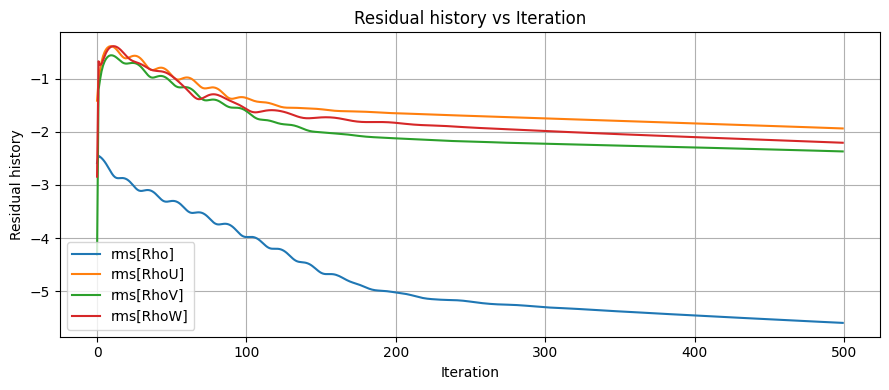

Saved: /content/diamond_wing_SU2/residual_history.png

RESULTS AND GRAPHS ADDED TO PROJECT ZIP.


In [28]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import zipfile

folder = "/content/diamond_wing_SU2"
history_file = folder + "/history.csv"

# Read SU2 results
df = pd.read_csv(history_file)
df.columns = [c.strip().strip('"') for c in df.columns]

print("AVAILABLE RESULT COLUMNS:")
print(df.columns.tolist())

print("\nLAST 10 SOLVER ITERATIONS:")
display(df.tail(10))

# Identify aerodynamic coefficient columns
columns = list(df.columns)
lower = {c: c.lower() for c in columns}

cl_cols = [c for c in columns if "cl" in lower[c] or "lift" in lower[c]]
cd_cols = [c for c in columns if "cd" in lower[c] or "drag" in lower[c]]
res_cols = [c for c in columns if "rms" in lower[c] or "res" in lower[c]]

# Plot lift and drag history where available
for label, selected in [("Lift coefficient", cl_cols),
                        ("Drag coefficient", cd_cols),
                        ("Residual history", res_cols[:4])]:
    if selected:
        plt.figure(figsize=(9, 4))
        for col in selected:
            values = pd.to_numeric(df[col], errors="coerce")
            plt.plot(values, label=col)
        plt.xlabel("Iteration")
        plt.ylabel(label)
        plt.title(label + " vs Iteration")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        filename = folder + "/" + label.lower().replace(" ", "_") + ".png"
        plt.savefig(filename, dpi=200)
        plt.show()
        print("Saved:", filename)

# Save a concise results summary
summary = df.tail(1)
summary.to_csv(folder + "/final_iteration_summary.csv", index=False)

# Add generated graphs and summary to project ZIP
zip_path = "/content/Flat_Plate_CFD_Project_Results.zip"
with zipfile.ZipFile(zip_path, "a", zipfile.ZIP_DEFLATED) as z:
    for name in os.listdir(folder):
        if name.endswith(".png") or name == "final_iteration_summary.csv":
            z.write(folder + "/" + name, name)

print("\nRESULTS AND GRAPHS ADDED TO PROJECT ZIP.")
